In [1]:
# Build and Train a Feedforward Neural Network
# o Use PyTorch or TensorFlow to build an MLP.
# o Train on MNIST or Fashion-MNIST dataset.
# o Tune hidden layers and activation functions.
# o Report accuracy and loss curves.

In [5]:
!pip install tensorflow numpy

Defaulting to user installation because normal site-packages is not writeable

  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
jax 0.7.1 requires ml_dtypes>=0.5.0, but you have ml-dtypes 0.4.1 which is incompatible.
jaxlib 0.7.1 requires ml_dtypes>=0.5.0, but you have ml-dtypes 0.4.1 which is incompatible.
mysql-connector-python 8.2.0 requires protobuf<=4.21.12,>=4.21.1, but you have protobuf 4.25.9 which is incompatible.
onnx 1.22.0 requires ml_dtypes>=0.5.4, but you have ml-dtypes 0.4.1 which is incompatible.
opentelemetry-exporter-otlp-proto-grpc 1.42.1 requires opentelemetry-exporter-otlp-proto-common==1.42.1, but you have opentelemetry-exporter-otlp-proto-common 1.45.1 which is incompatible.
opentelemetry-exporter-otlp-proto-grpc 1.42.1 requires opentelemetry-proto==1.42.1, but you have opentelemetry-proto 1.45.1 which is incompatible.
opentelemetry-exporter-ot


  Attempting uninstall: protobuf
    Found existing installation: protobuf 5.29.6
    Uninstalling protobuf-5.29.6:
      Successfully uninstalled protobuf-5.29.6
  Attempting uninstall: ml-dtypes
    Found existing installation: ml_dtypes 0.5.4
    Uninstalling ml_dtypes-0.5.4:
      Successfully uninstalled ml_dtypes-0.5.4


In [6]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
# load the MNIST
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


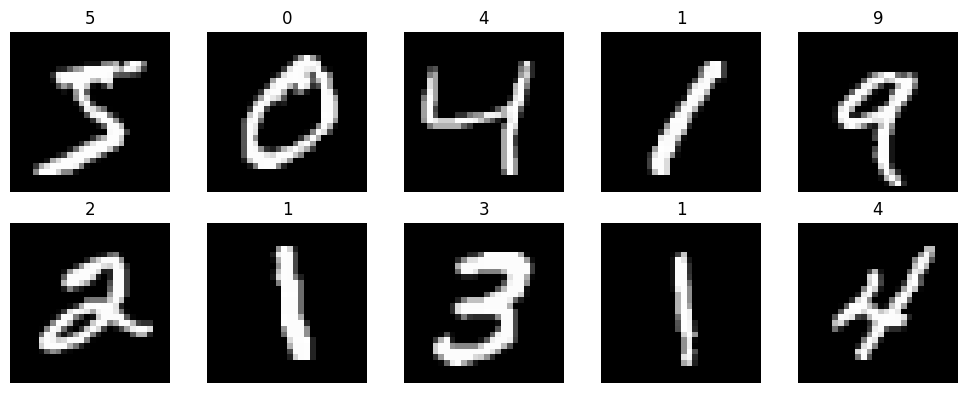

In [8]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(y_train[i])
    plt.axis("off")
    
plt.tight_layout()
plt.show()

In [9]:
# preprocess the data
x_test = x_test.astype("float32") / 255.0
x_train = x_train.astype("float32") / 255.0

In [14]:
# Build the MLP model
# Our neural network will have:
# 1. Input layer: 784 neurons
# 2. Hidden layer: 128 neurons
# 3. Hidden layer: 64 neurons
# 4. Output layer: 10 neurons

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28,28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax"),
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [21]:
start_time = time.time()

history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)
end_time = time.time()

total_time = end_time - start_time
print(f"Total time to train model: {total_time}")

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9953 - loss: 0.0164 - val_accuracy: 0.9758 - val_loss: 0.0973
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9950 - loss: 0.0161 - val_accuracy: 0.9797 - val_loss: 0.0897
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9964 - loss: 0.0137 - val_accuracy: 0.9782 - val_loss: 0.1009
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9969 - loss: 0.0103 - val_accuracy: 0.9778 - val_loss: 0.0999
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9956 - loss: 0.0130 - val_accuracy: 0.9798 - val_loss: 0.1030
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9975 - loss: 0.0089 - val_accuracy: 0.9800 - val_loss: 0.1025
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9981 - loss: 0.0067 - val_accuracy: 0.9795 - val_loss: 0.1123
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9976 - loss: 0.0076 - val_accuracy: 0.

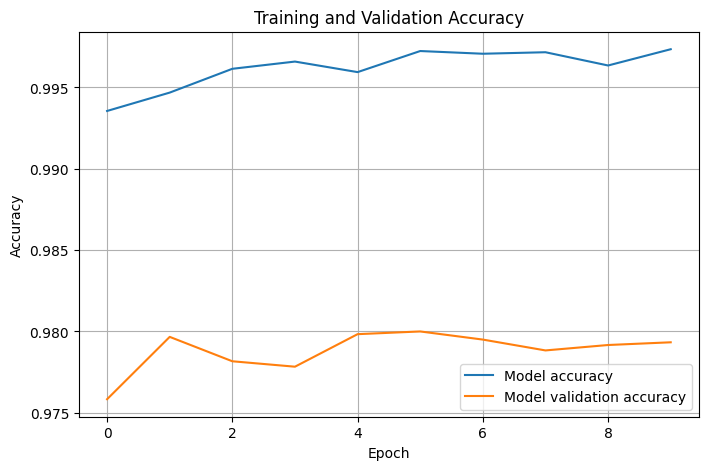

In [22]:

import matplotlib.pyplot as plt

hist = history.history

plt.figure(figsize=(8, 5))
plt.plot(hist["accuracy"], label="Model accuracy")
plt.plot(hist["val_accuracy"], label="Model validation accuracy")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


In [24]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_acc * 100, 2), "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9735 - loss: 0.1462
Test Loss: 0.1204
Test Accuracy: 97.62 %


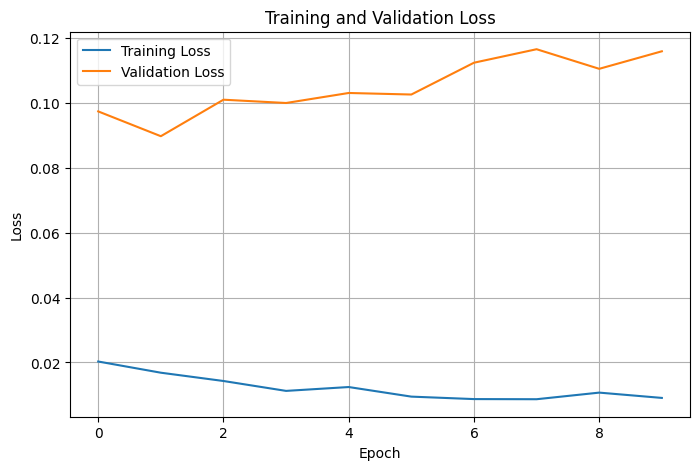

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()